## Nội dung

- Feature engineering
- Phân cụm: KMeans, DBSCAN
- Kết hợp phân cụm và phân tích mô tả
- Kết hợp PCA và phân cụm
- Tập dữ liệu:
   1. Customer Personality Analysis (nguồn: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)
   2. Taxi geolocation (nguồn: https://www.coursera.org/projects/clustering-geolocation-data-intelligently-python)

#### Cài đặt thư viện

In [95]:
!pip install folium
!pip install kneed
!pip install yellowbrick

You should consider upgrading via the 'C:\Users\lenovo\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'C:\Users\lenovo\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'C:\Users\lenovo\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


### A. Customer Personality Analysis

#### A1. Đọc dữ liệu

In [96]:
import numpy as np
import pandas as pd

In [97]:
pd.set_option('display.max_columns', None)
customer_data = pd.read_csv('data/marketing_campaign.csv',
                           delimiter='\t', index_col='ID')
customer_data.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


#### A2. Làm sạch
- Làm sạch dữ liệu.
- Trích xuất đặc trưng (đọc thêm: https://machinelearningcoban.com/general/2017/02/06/featureengineering/)

In [98]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2240 entries, 5524 to 9405
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2240 non-null   int64  
 1   Education            2240 non-null   object 
 2   Marital_Status       2240 non-null   object 
 3   Income               2216 non-null   float64
 4   Kidhome              2240 non-null   int64  
 5   Teenhome             2240 non-null   int64  
 6   Dt_Customer          2240 non-null   object 
 7   Recency              2240 non-null   int64  
 8   MntWines             2240 non-null   int64  
 9   MntFruits            2240 non-null   int64  
 10  MntMeatProducts      2240 non-null   int64  
 11  MntFishProducts      2240 non-null   int64  
 12  MntSweetProducts     2240 non-null   int64  
 13  MntGoldProds         2240 non-null   int64  
 14  NumDealsPurchases    2240 non-null   int64  
 15  NumWebPurchases      2240 non-null   int

Dữ liệu khá sạch và chỉ có 1 số lượng nhỏ income bị thiếu dữ liệu, có thể xử lý bằng cách thêm vào mean. Mã hoá 1 số đặc trưng kiểu loại.

In [99]:
# Xử lý dữ liệu khuyết cho Income bằng cách thêm mean
customer_data['Income'] = customer_data['Income'].fillna(
    customer_data['Income'].mean()
)

customer_data[['Income']].head()

customer_data['Income'] = customer_data['Income'].astype(float)

In [100]:
import datetime

Đầu tiên là dữ liệu liên quan ngày tháng.

- `Year_Birth` không phải là đặc trưng lý tưởng cho bài toán này, ta sẽ chuyển nó sang thành tuổi `Age` (tính từ hiện tại)

In [101]:
# Trích xuất tuổi từ đặc trưng năm sinh
# hint: 2022 - x

customer_data['Age'] = 2022 - customer_data['Year_Birth']

customer_data['Age'] = customer_data['Age'].clip(
    lower=18,
    upper=100
)

# Chuyển Dt_Customer sang kiểu datetime
customer_data['Dt_Customer'] = pd.to_datetime(
    customer_data['Dt_Customer'],
    format='%d-%m-%Y'
)

# Chuyển đổi ngày tham gia thành số ngày đã tham gia
customer_data['Enroll_Days'] = (
    pd.Timestamp('2022-01-01') - customer_data['Dt_Customer']
).dt.days

customer_data[['Age', 'Enroll_Days']].head()

,Age,Enroll_Days
ID,,
5524,65,3406
2174,68,2856
4141,57,3055
6182,38,2882
5324,41,2904


- `Days_Since_Customer`, tương tự như `Year_Birth`, nên được chuyển thành số ngày đã tham gia `Enroll_days`.

- Các đặc trưng `Marital_Status`, `Kidhome`, `Teenhome` có thể được gom lại 1 thuộc tính duy nhất --> cô động hơn

In [102]:
# Tạo ra đặc trưng Fam_size (số người trong gia đình)
# bằng cách gộp các đặc trưng: Martial_Status, Kidhome, Teenhome
marital_map = {
    'Absurd': 1, 'Alone': 1,
    'YOLO': 1, 'Single': 1,
    'Married': 2, 'Together': 2,
    'Widow': 1, 'Divorced': 1
} # married/together->2 người, khác-> 1 người
customer_data['Marital_Status'] = customer_data['Marital_Status'].map(marital_map).fillna(1)
customer_data['Fam_Size'] = customer_data['Marital_Status'] + customer_data['Kidhome'] + customer_data['Teenhome']
customer_data[['Marital_Status', 'Kidhome', 'Teenhome', 'Fam_Size']].head()

,Marital_Status,Kidhome,Teenhome,Fam_Size
ID,,,,
5524,1,0,0,1
2174,1,1,1,3
4141,2,0,0,2
6182,2,1,0,3
5324,2,1,0,3


In [103]:
# Num_Accepted = AcceptedCmp1 + AcceptedCmp2 + ... + Response
customer_data['Num_Accepted'] = customer_data[[f'AcceptedCmp{i}' for i in range(1, 6)]].sum(axis=1) + customer_data['Response']
customer_data['Num_Accepted'].head()

ID
5524    1
2174    0
4141    0
6182    0
5324    0
Name: Num_Accepted, dtype: int64

In [104]:
# Có thể gộp các đặc trưng MntXXX thành 1 thuộc tính duy nhất (tính tổng)
customer_data['MntTotal'] = customer_data[[col for col in customer_data.columns if col.startswith('Mnt')]].sum(axis=1)
customer_data['MntTotal'].head()

ID
5524    1617
2174      27
4141     776
6182      53
5324     422
Name: MntTotal, dtype: int64

In [105]:
customer_data.describe()

,Year_Birth,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Enroll_Days,Fam_Size,Num_Accepted,MntTotal
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,1968.805804,1.644643,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142784,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107,53.161161,3096.582143,2.595089,0.446875,605.798214
min,1893.000000,1.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,26.000000,2743.000000,1.000000,0.000000,5.000000
25%,1959.000000,1.000000,35538.750000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,45.000000,2923.750000,2.000000,0.000000,68.750000
50%,1970.000000,2.000000,51741.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,52.000000,3098.500000,3.000000,0.000000,396.000000
75%,1977.000000,2.000000,68289.750000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,63.000000,3272.000000,3.000000,1.000000,1045.500000
max,1996.000000,2.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,100.000000,3442.000000,5.000000,5.000000,2525.000000
std,11.984069,0.478728,25037.797168,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274,11.819259,202.122512,0.906959,0.890543,602.249288


In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [107]:
# Xử lý nhiễu (nếu có): giới hạn tuổi và thu nhập hợp lý

customer_data['Age'] = customer_data['Age'].clip(
    lower=18,
    upper=100
)

customer_data['Income'] = customer_data['Income'].clip(
    lower=0,
    upper=customer_data['Income'].quantile(0.99)
)

customer_data[['Age', 'Income']].describe()

,Age,Income
count,2240.000000,2240.000000
mean,53.161161,51760.956997
std,11.819259,20648.649490
min,26.000000,1730.000000
25%,45.000000,35538.750000
50%,52.000000,51741.500000
75%,63.000000,68289.750000
max,100.000000,94437.680000


#### A5. Tiền xử lý

**Mã hoá đặc trưng kiểu loại**

In [108]:
# TODO
df = customer_data.copy()

# Xử lý giá trị thiếu
df = df.fillna(df.mean(numeric_only=True))

# Mã hóa Education
df = pd.get_dummies(
    df,
    columns=['Education'],
    drop_first=True
)

# Chọn các cột cần dùng
df = df[
    [
        'Income',
        'Age',
        'Enroll_Days',
        'Fam_Size',
        'Num_Accepted',
        'MntTotal',
        'NumCatalogPurchases',
        'NumStorePurchases',
        'NumWebVisitsMonth',
        'Recency',
        'NumDealsPurchases',
        'NumWebPurchases'
    ]
]

**Chuẩn hoá các thuộc tính kiểu số**

In [109]:
df.describe() # --> Kiểm tra mean và std có gần với giá trị (0, 1)?

,Income,Age,Enroll_Days,Fam_Size,Num_Accepted,MntTotal,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Recency,NumDealsPurchases,NumWebPurchases
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,51760.956997,53.161161,3096.582143,2.595089,0.446875,605.798214,2.662054,5.790179,5.316518,49.109375,2.325000,4.084821
std,20648.649490,11.819259,202.122512,0.906959,0.890543,602.249288,2.923101,3.250958,2.426645,28.962453,1.932238,2.778714
min,1730.000000,26.000000,2743.000000,1.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35538.750000,45.000000,2923.750000,2.000000,0.000000,68.750000,0.000000,3.000000,3.000000,24.000000,1.000000,2.000000
50%,51741.500000,52.000000,3098.500000,3.000000,0.000000,396.000000,2.000000,5.000000,6.000000,49.000000,2.000000,4.000000
75%,68289.750000,63.000000,3272.000000,3.000000,1.000000,1045.500000,4.000000,8.000000,7.000000,74.000000,3.000000,6.000000
max,94437.680000,100.000000,3442.000000,5.000000,5.000000,2525.000000,28.000000,13.000000,20.000000,99.000000,15.000000,27.000000


In [110]:
from sklearn.cluster import KMeans

Phương pháp Elbow: ước lượng số cụm

In [111]:

X = df.to_numpy(dtype=float)

X_scaled = StandardScaler().fit_transform(X)

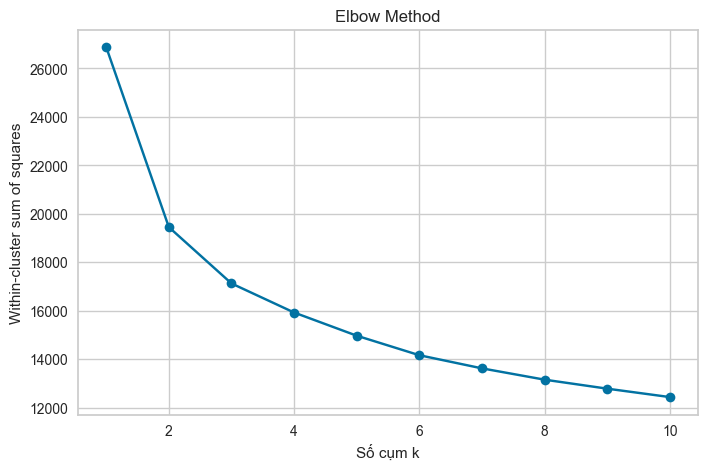

In [112]:
# TODO - vẽ biểu đồ elbow để ước lượng số cụm

sse = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    kmeans.fit(X_scaled)

    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    sse,
    marker='o'
)

plt.title('Elbow Method')
plt.xlabel('Số cụm k')
plt.ylabel('Within-cluster sum of squares')
plt.grid(True)

plt.show()

Sử dụng thư viện yellowbrick

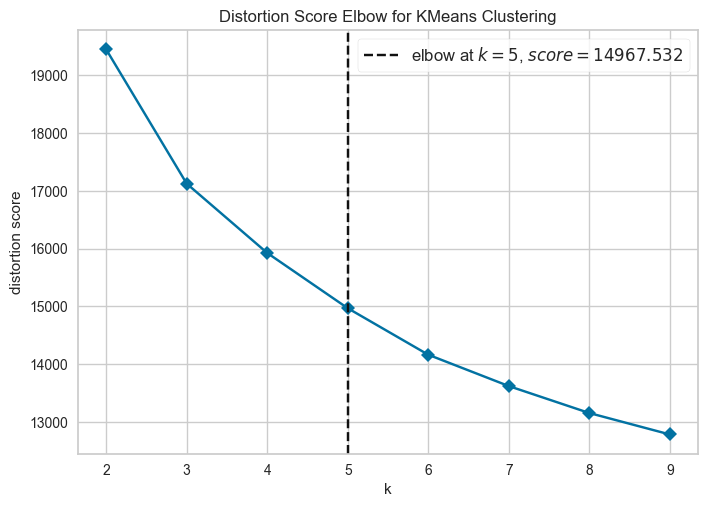

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [113]:
# TODO

from yellowbrick.cluster import KElbowVisualizer

model = KMeans(
    n_init=20,
    random_state=42
)

visualizer = KElbowVisualizer(
    model,
    k=(2, 10),
    metric='distortion',
    timings=False
)

visualizer.fit(X_scaled)

visualizer.show()

**Phân cụm từ kết quả của phương pháp Elbow**

**Sử dụng PCA giảm số chiều dữ liệu --> trực quan hoá kết quả phân cụm**

In [114]:
from sklearn.decomposition import PCA

In [115]:
# Biến đổi dữ liệu sang không gian 2 chiều pca
# TODO
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

**Trực quan hoá kết quả phân cụm**

In [116]:
def visualize_cluster_result(scores, labels):
    '''
    Args:
        scores: biến đổi pca 2d
        labels: nhãn của từng điểm dữ liệu trong scores (chính là label của kết quả phân cụm)
    '''
    # TODO
    fig1, (axes) = plt.subplots(figsize=(8,8))
    scat_1 = sns.scatterplot(
                            x=scores[:,0],
                            y=scores[:,1],
                            hue=labels, ax=axes,
                            palette='Set1', legend='full'
            )
    plt.show()

In [117]:
from sklearn.cluster import KMeans

kmean = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=42
)

kmean.fit(X_scaled)

KMeans(n_clusters=3, n_init=20, random_state=42)

In [118]:
# Gán kết quả phân cụm vào df ban đầu ~ customer_data
kmean_df = customer_data.copy()
kmean_df['Cluster'] = kmean.labels_
kmean_df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Enroll_Days,Fam_Size,Num_Accepted,MntTotal,Cluster
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5524,1957,Graduation,1,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,65,3406,1,1,1617,0
2174,1954,Graduation,1,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,68,2856,3,0,27,1
4141,1965,Graduation,2,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,57,3055,2,0,776,2
6182,1984,Graduation,2,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,38,2882,3,0,53,1
5324,1981,PhD,2,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,41,2904,3,0,422,2


In [119]:
def visualize_cluster_distribution(labels):
    '''
    Args:
        labels: kết quả phân cụm (danh sách nhãn)
    '''
    ulabels, count = np.unique(labels, return_counts=True)
    plt.figure(figsize=(6,4))

    colors = sns.color_palette('Set2')[0:5]
    
    labels = [f'Cluster {i+1}' for i in range(len(ulabels))]
    plt.pie(count, 
            explode=[0.05]*len(ulabels), 
            labels=labels,
            colors=colors,
            autopct='%1.1f%%',
            textprops=dict(color ="white", fontsize=10),
            counterclock=False,
            startangle=180,
            wedgeprops={"edgecolor":"gray",'linewidth': 1}
        )

    plt.axis('equal')
    plt.legend()
    plt.show()

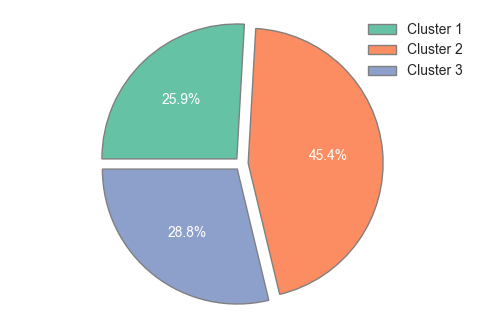

In [120]:
visualize_cluster_distribution(kmean.labels_)

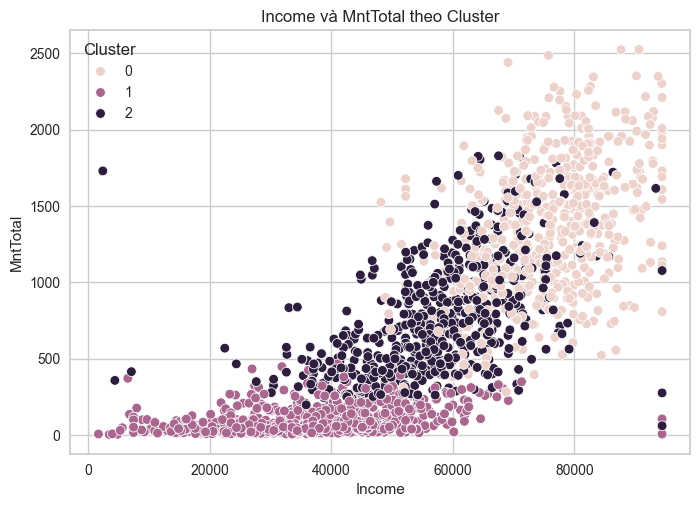

In [121]:
# đặc trưng income và MntTotal: vẽ sns scatterplot với hue là Cluster
# TODO
sns.scatterplot(
    data=kmean_df,
    x='Income',
    y='MntTotal',
    hue='Cluster'
)

plt.title('Income và MntTotal theo Cluster')
plt.xlabel('Income')
plt.ylabel('MntTotal')
plt.show()

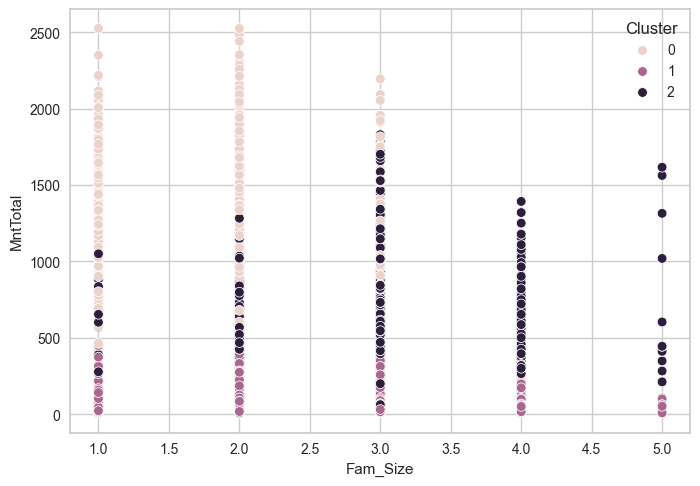

In [122]:
# đặc trưng Fam_Size và MntTotal: vẽ sns scatterplot với hue là Cluster
# TODO
sns.scatterplot(
    data=kmean_df,
    x='Fam_Size',
    y='MntTotal',
    hue='Cluster'
)
plt.show()

In [123]:
# TODO

#### A7. Kết hợp PCA và phân cụm
- Biến đổi PCA với số lượng component phù hợp (giữ lại 70-80% thông tin ban đầu).
- Ước lượng số cụm dùng elbow (dùng dữ liệu pca).
- Với số cụm phù hợp, thực hiện phân cụm trên dữ liệu pca.
- Vẽ phân bố kết quả phân cụm.
- Vẽ biểu đồ scatter MntTotal-Income-Cluster.

In [124]:
# vẽ biểu đồ sreeplot
def scree_plot(pca_model, xlabels):
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # explained variance ratio của mô hình pca
    expl_var_ratio = pca_model.explained_variance_ratio_
    # tính cumulative sum của expl_var_ratio (numpy.cumsum)
    expl_var_cumsum = np.cumsum(expl_var_ratio)
    xtick_indx = range(1, len(expl_var_ratio) + 1)
    
    # vẽ các bar thể hiện explained_var
    ax.bar(xtick_indx, expl_var_ratio)
    ax.plot(xtick_indx, expl_var_cumsum, marker='o', color='k')
    
    # set label
    ax.set_xticks(xtick_indx)
    ax.set_xticklabels(xlabels)
    ax.set_xlabel('Principle Components')
    ax.set_ylabel('% variance')
    ax.set_title('Scree Plot')
    
    plt.grid(True)

In [125]:
# biến đổi df sang không gian pca 4 chiều
pca_4d = PCA(n_components=4)
pca_transformed_4d = pca_4d.fit_transform(X_scaled)
pca_transformed_4d.shape

(2240, 4)

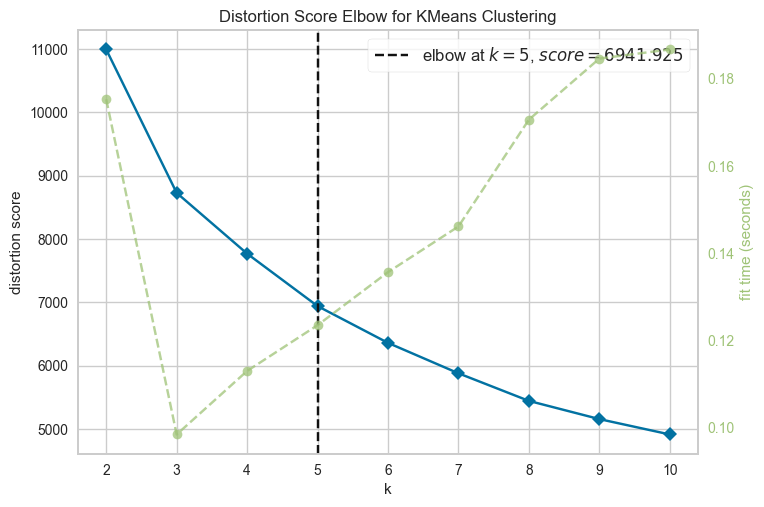

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [126]:
model = KMeans(n_init=20, random_state=99)
visualizer = KElbowVisualizer(model, k=10)
visualizer.fit(pca_transformed_4d)
visualizer.show()

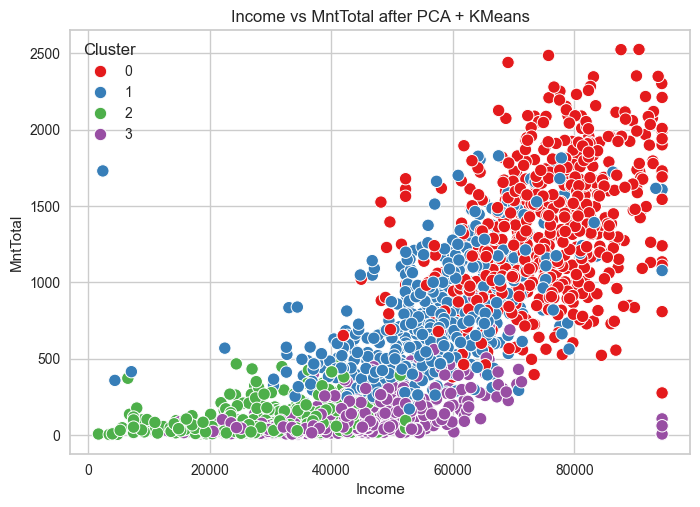

In [127]:
# đặc trưng income và MntTotal: vẽ sns scatterplot với hue là Cluster

pca_cluster_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

pca_cluster_model.fit(pca_transformed_4d)

pca_cluster_df = customer_data.copy()

pca_cluster_df['Cluster'] = pca_cluster_model.labels_

sns.scatterplot(
    data=pca_cluster_df,
    x='Income',
    y='MntTotal',
    hue='Cluster',
    s=80,
    palette='Set1'
)

plt.title('Income vs MntTotal after PCA + KMeans')
plt.show()

#### A9. Phân tích kết quả phân cụm (DBSCAN)

In [128]:
from sklearn.cluster import DBSCAN

**Sử dụng knee plot để ước lượng eps**

In [129]:
len(df.columns)

12

In [130]:
from sklearn.neighbors import NearestNeighbors
def knee_plot(n_neighs, data):
    neigh = NearestNeighbors(n_neighbors=n_neighs)
    nbrs = neigh.fit(data)
    distances, indices = nbrs.kneighbors(data)

    # plot
    distances = np.sort(distances, axis=0)
    distances = distances[:,1]
    plt.plot(distances)
    
    return distances

**Sử dụng PCA thu giảm số chiều --> phân cụm**

**Chia nhỏ đặc trưng**

### B. Dữ liệu taxi 

In [131]:
import pandas as pd

In [132]:
df = pd.read_csv('data/taxi_data.csv')
df.head()

,LON,LAT,NAME
0,28.17858,-25.73882,11th Street Taxi Rank
1,28.17660,-25.73795,81 Bazaar Street Taxi Rank
2,27.83239,-26.53722,Adams Road Taxi Rank
3,28.12514,-26.26666,Alberton City Mall Taxi Rank
4,28.10144,-26.10567,Alexandra Main Taxi Rank


**Biểu diễn giá trị toạ độ trên bản đồ**

In [133]:
import folium, re

In [134]:
print(df[['LAT', 'LON']].isna().sum())

LAT    1
LON    1
dtype: int64


In [145]:
X = df[['LAT', 'LON']].dropna().to_numpy()
m = folium.Map(location=[X[:, 0].mean(), X[:, 1].mean()], tiles='OpenStreetMap', zoom_start=10)

In [ ]:
clean_df = df[['LAT', 'LON', 'NAME']].dropna().copy()

for _, row in clean_df.iterrows():
    folium.CircleMarker(
        location=[row.LAT, row.LON],
        radius=5,
        popup=re.sub(r'\W+', ' ', row.NAME),
        fill=True
    ).add_to(m)

# Loại bỏ non-word chars
title = '''<h3 align="center" style="font-size:30px"><b>Given Data</b></h3>'''

m.get_root().html.add_child(folium.Element(title))
m

In [148]:
#First create an array of color schemes
colors = ['royalblue', 'maroon', 'forestgreen', 'mediumorchid', 'tan', 'deeppink', 
          'olive', 'goldenrod', 'lightcyan', 'navy','springgreen','midnightblue',
         'red','brown','limegreen','lime','pink','orchid','crimson','m']*10

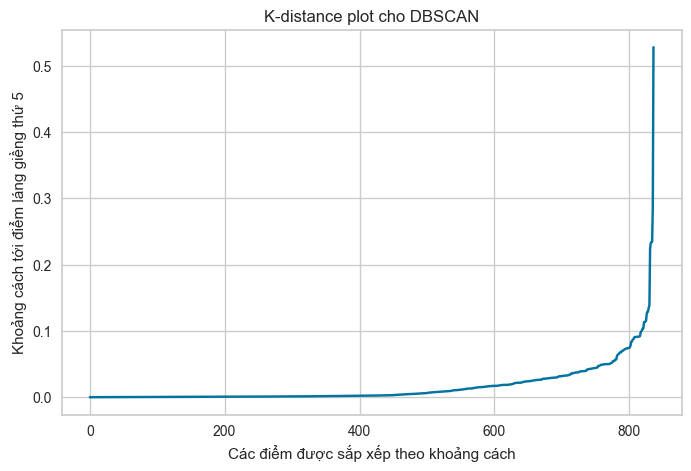

Unique labels: [-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46
 47 48 49 50]
Counts: [288  31   6   7  17   9   6   6   7   9  77   5  10   7   8   5   5  10
   8   8   9   7   7   6  13   6   7   8   7   7   6  15  22  14  18  10
   8  14   6   5  10  26   7  12   7   8   7   8   5  12   6   5]
Số cụm hợp lệ: 51
Số điểm nhiễu (-1): 288


In [149]:
# Sử dụng DBSCAN để phân cụm
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

coords = df[['LAT', 'LON']].dropna().to_numpy()

# Vẽ knee plot để ước lượng eps
n_neighbors = 5
nbrs = NearestNeighbors(n_neighbors=n_neighbors)
nbrs_fit = nbrs.fit(coords)
distances, _ = nbrs_fit.kneighbors(coords)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-distance plot cho DBSCAN')
plt.xlabel('Các điểm được sắp xếp theo khoảng cách')
plt.ylabel('Khoảng cách tới điểm láng giềng thứ 5')
plt.grid(True)
plt.show()

# Chọn eps phù hợp và thực hiện DBSCAN
# Với dữ liệu GPS, khoảng cách 0.01 độ xấp xỉ 1 km ở vĩ độ ~25°
eps_value = 0.01
min_samples = 5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
labels = dbscan.fit_predict(coords)

unique_labels, counts = np.unique(labels, return_counts=True)
print('Unique labels:', unique_labels)
print('Counts:', counts)
print('Số cụm hợp lệ:', len(unique_labels[unique_labels != -1]))
print('Số điểm nhiễu (-1):', np.sum(labels == -1))

# Tạo bản đồ kết quả phân cụm
cluster_df = df[['LAT', 'LON', 'NAME']].dropna().copy()
cluster_df['Cluster'] = labels

m_dbscan = folium.Map(
    location=[coords[:, 0].mean(), coords[:, 1].mean()],
    tiles='OpenStreetMap',
    zoom_start=10
)

for _, row in cluster_df.iterrows():
    cluster_id = int(row['Cluster'])
    color = 'black' if cluster_id == -1 else colors[cluster_id % len(colors)]
    folium.CircleMarker(
        location=[row['LAT'], row['LON']],
        radius=5,
        popup=f"{row['NAME']} | Cluster {cluster_id}",
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8
    ).add_to(m_dbscan)

# Gắn tiêu đề cho bản đồ
map_title = '''<h3 align="center" style="font-size:30px"><b>DBSCAN Clusters</b></h3>'''
m_dbscan.get_root().html.add_child(folium.Element(map_title))
m_dbscan

In [144]:
# Có thể thử lại với các giá trị eps khác nhau để so sánh
for eps_try in [0.005, 0.01, 0.02, 0.03]:
    labels_try = DBSCAN(eps=eps_try, min_samples=5).fit_predict(coords)
    n_clusters = len(np.unique(labels_try[labels_try != -1]))
    n_noise = np.sum(labels_try == -1)
    print(f'eps={eps_try:.3f} -> số cụm={n_clusters}, nhiễu={n_noise}')

eps=0.005 -> số cụm=49, nhiễu=344
eps=0.010 -> số cụm=51, nhiễu=288
eps=0.020 -> số cụm=51, nhiễu=181
eps=0.030 -> số cụm=41, nhiễu=122
